<a href="https://colab.research.google.com/github/zyamjadoon1/DATA201-LABS/blob/main/Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA 201 - Week 9 Homework: Decision Trees

**Name:** Zyam Khawaja
**Dataset:** Carseats (ISLP)
**Goal:** Build and evaluate a decision tree that predicts High Sales vs. Low Sales, then explore how tree depth affects overfitting

In [ ]:
try:
    import ISLP
except ImportError:
    %pip install -q ISLP

## Part 1 - Build a Classification Tree

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ISLP import load_data
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Load the data and create the binary target: HighSales = 1 if Sales > 8, else 0
Carseats = load_data("Carseats")
Carseats["HighSales"] = (Carseats["Sales"] > 8).astype(int)
print(Carseats["HighSales"].value_counts())

# 2. Encode categorical predictors (ShelveLoc, Urban, US) as 0/1 dummy variables.
#    Sales is dropped from the predictors because HighSales is made from it.
y = Carseats["HighSales"]
X = pd.get_dummies(Carseats.drop(columns=["Sales", "HighSales"]), drop_first=True).astype(float)
print(X.columns.tolist())

HighSales
0    236
1    164
Name: count, dtype: int64
['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education', 'ShelveLoc_Good', 'ShelveLoc_Medium', 'Urban_Yes', 'US_Yes']


In [ ]:
# 3. Split into 70% training and 30% test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])

Training rows: 280 | Test rows: 120


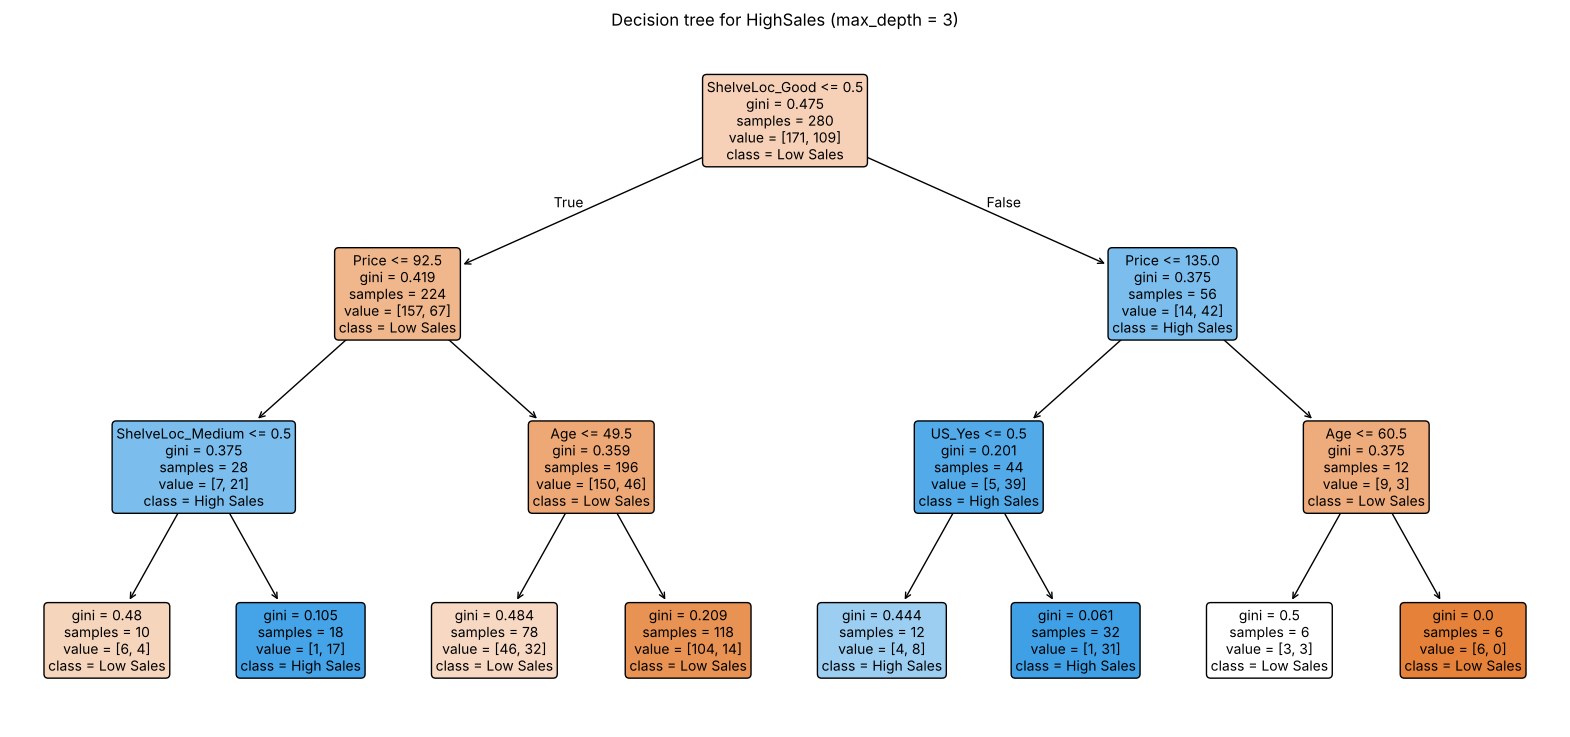

Training accuracy: 0.7893
Test accuracy:     0.7167


In [ ]:
# 4. Train a DecisionTreeClassifier with max_depth=3
tree3 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree3.fit(X_train, y_train)

# 5. Plot the tree and report training and test accuracy
plt.figure(figsize=(20, 9))
plot_tree(tree3, feature_names=X.columns, class_names=["Low Sales", "High Sales"],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision tree for HighSales (max_depth = 3)")
plt.show()

print("Training accuracy:", round(tree3.score(X_train, y_train), 4))
print("Test accuracy:    ", round(tree3.score(X_test, y_test), 4))

## Part 2 - Investigate Overfitting

In [ ]:
# 1-2. Train trees with max_depth 1..10 and use 5-fold cross-validation on the TRAINING data
depths = range(1, 11)
cv_scores = []
for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_scores.append(cross_val_score(model, X_train, y_train, cv=5).mean())

cv_table = pd.DataFrame({"max_depth": list(depths), "mean CV accuracy": np.round(cv_scores, 4)})
cv_table

,max_depth,mean CV accuracy
0,1,0.6821
1,2,0.7321
2,3,0.7250
3,4,0.7071
4,5,0.7000
5,6,0.7286
6,7,0.7143
7,8,0.7000
8,9,0.7071
9,10,0.7107


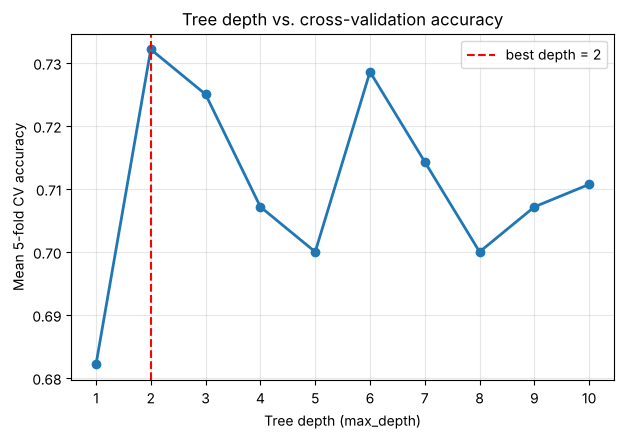

Best depth: 2 | CV accuracy: 0.7321


In [ ]:
# 3. Graph: tree depth vs. cross-validation accuracy
best_depth = list(depths)[int(np.argmax(cv_scores))]
plt.figure(figsize=(7, 4.5))
plt.plot(list(depths), cv_scores, marker="o", linewidth=2)
plt.axvline(best_depth, color="red", linestyle="--", label=f"best depth = {best_depth}")
plt.xticks(list(depths))
plt.xlabel("Tree depth (max_depth)")
plt.ylabel("Mean 5-fold CV accuracy")
plt.title("Tree depth vs. cross-validation accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 4. Best depth based on cross-validation
print("Best depth:", best_depth, "| CV accuracy:", round(max(cv_scores), 4))

In [ ]:
# 5. Train the final tree with the best depth and evaluate it on the test set
final_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
final_tree.fit(X_train, y_train)
print("Final tree (depth =", best_depth, ")")
print("Training accuracy:", round(final_tree.score(X_train, y_train), 4))
print("Test accuracy:    ", round(final_tree.score(X_test, y_test), 4))

# For comparison: a tree with no depth limit
full_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print()
print("Full tree (no limit, depth =", full_tree.get_depth(), ")")
print("Training accuracy:", round(full_tree.score(X_train, y_train), 4))
print("Test accuracy:    ", round(full_tree.score(X_test, y_test), 4))

Final tree (depth = 2 )
Training accuracy: 0.7821
Test accuracy:     0.725

Full tree (no limit, depth = 11 )
Training accuracy: 1.0
Test accuracy:     0.65


## Part 3 - Answers

**1. Interpreting the tree: Which predictor was selected for the first split (root)? What does this split tell us about sales?**

The root split is on `ShelveLoc_Good` (is the shelving location "Good"?). The algorithm picks the split that separates High Sales from Low Sales best, so shelf location is the most informative predictor of sales. Stores with a Good shelf location are much more likely to have High Sales (Sales > 8), while stores with a Bad or Medium shelf location are mostly Low Sales. After that, `Price` is used on both sides, so a lower price also goes with higher sales.

**2. Choosing tree depth: According to your cross-validation graph, which depth performed best? Why should we use cross-validation rather than test accuracy to choose the depth?**

Depth **2** had the highest mean cross-validation accuracy (73.2%). We should use cross-validation instead of test accuracy because the test set must stay untouched until the very end. If we pick the depth that scores best on the test set, we have tuned the model to that test data, and the test accuracy becomes an optimistic estimate instead of an honest measure of how the model does on new data. Cross-validation tunes the depth using only the training data (several different validation folds), and it is more stable than a single split. The final test score of the chosen tree (72.5%) is then an unbiased estimate.

**3. Overfitting: Does increasing tree depth always improve cross-validation accuracy? Explain using your graph.**

No. On the graph, cross-validation accuracy goes up from depth 1 (68.2%) to its peak at depth 2 (73.2%), but then it does not keep improving. It goes up and down and ends at 71.1% at depth 10, below the peak. Deeper trees fit the training data better (an unlimited tree reaches 100.0% training accuracy at depth 11) but they start fitting noise in the training data, so they do worse on data they have not seen (the unlimited tree gets only 65.0% on the test set). That gap between training and validation accuracy is overfitting. A shallow tree is simpler and generalizes better.

---

## Wrap-up questions (from the Decision Tree lab)

**1. What does a leaf predict in a classification tree? In a regression tree?**

In a classification tree, a leaf predicts the majority class of the training observations that land in it (for example, High Sales or Low Sales). In a regression tree, a leaf predicts the mean of the target values of the training observations in it.

**2. Why did the full tree reach 100% training accuracy but do worse on the test set?**

The full tree keeps splitting until every leaf is pure, so it memorizes the training data, including its noise, and gets 100% training accuracy. That memorized pattern does not hold for new data, so it does worse on the test set. This is overfitting (low bias, high variance).

**3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?**

Two ways: (1) set a maximum depth (`max_depth`), and (2) require a minimum number of samples per leaf or per split (`min_samples_leaf` / `min_samples_split`), or prune the tree (`ccp_alpha`). Cross-validation helped me tune the maximum depth (`max_depth`).

**4. Why do we not need to scale features before fitting a tree?**

A tree splits on one feature at a time using a threshold ("is Price <= 101.5?"), and only the order of the values matters. Rescaling a feature does not change the order of its values, so the same splits are found. Unlike methods based on distances or coefficient size (like KNN, Lasso, or Ridge), trees do not depend on the units or scale of the features.

**5. A teammate says "Age has importance 0, so it is irrelevant to heart disease." What is wrong with that claim?**

An importance of 0 only means that this tree never used Age to split, so it never reduced impurity (Gini/entropy) in this model. It does not mean Age has no relationship with heart disease. Age could be correlated with another feature the tree used instead (for example, max heart rate or blood pressure), so the tree got the same impurity reduction from that feature. With a different tree, depth, or sample, Age could be chosen. So zero importance means "not needed in this tree," not "irrelevant."

**6. Name one strength and one weakness of a single decision tree that you saw in this lab.**

Strength: it is easy to interpret, because the tree can be plotted and read as simple if/then rules, and it needs no feature scaling. Weakness: it overfits easily, as the full tree showed (100% training accuracy but lower test accuracy), and it is unstable, since a small change in the data can give a very different tree.